In [1]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Math

def analizar_transformada_fourier(f_t, variable_t, lim_inf=-sp.oo, lim_sup=sp.oo, 
                                  t_rango=(-5, 5), w_rango=(-20, 20)):
    t = variable_t
    w = sp.Symbol('w', real=True)
    
    # 1. CÁLCULO SIMBÓLICO EXACTO
    integrando = f_t * sp.exp(-sp.I * w * t)
    F_w = sp.integrate(integrando, (t, lim_inf, lim_sup))
    
    # Forzar la resolución si la integral quedó expresada simbólicamente
    if F_w.has(sp.Integral):
        F_w = F_w.doit()
        
    # Extraer de forma inteligente la expresión que depende de 'w' del Piecewise
    if isinstance(F_w, sp.Piecewise):
        expr_encontrada = False
        for val, cond in F_w.args:
            if val.has(w):
                F_w = val
                expr_encontrada = True
                break
        if not expr_encontrada:
            F_w = F_w.args[0][0]
        
    # Reescribir exponenciales complejas en términos de cosenos/senos y simplificar
    F_w = sp.simplify(F_w.rewrite(sp.cos))
    
    mag_F = sp.Abs(F_w)
    fase_rad = sp.arg(F_w)
    fase_deg = sp.simplify(fase_rad * (180 / sp.pi))
    
    # 2. MOSTRAR RESULTADOS
    print("=" * 75)
    print(" RESULTADOS SIMBÓLICOS DE LA TRANSFORMADA")
    print("=" * 75)
    display(Math(rf"f(t) = {sp.latex(f_t)}"))
    display(Math(rf"F(\omega) = {sp.latex(F_w)}"))
    display(Math(rf"|F(\omega)| = {sp.latex(mag_F)}"))
    display(Math(rf"\angle F(\omega) = {sp.latex(fase_deg)}^\circ"))
    
    # 3. EVALUACIÓN NUMÉRICA
    f_t_num_expr = f_t.subs([(s, 1) for s in f_t.free_symbols if s != t])
    mag_num_expr = mag_F.subs([(s, 1) for s in mag_F.free_symbols if s != w])
    fase_deg_num_expr = fase_deg.subs([(s, 1) for s in fase_deg.free_symbols if s != w])
    
    f_num = sp.lambdify(t, f_t_num_expr, modules=['numpy'])
    mag_num = sp.lambdify(w, mag_num_expr, modules=['numpy'])
    fase_num = sp.lambdify(w, fase_deg_num_expr, modules=['numpy'])
    
    t_vals = np.linspace(t_rango[0], t_rango[1], 1000)
    w_vals = np.linspace(w_rango[0], w_rango[1], 1000)
    
    y_t = np.nan_to_num(np.vectorize(f_num)(t_vals), nan=0.0)
    y_mag = np.nan_to_num(np.vectorize(mag_num)(w_vals), nan=0.0)
    y_fase = np.nan_to_num(np.vectorize(fase_num)(w_vals), nan=0.0)

    # 4. GRAFICACIÓN
    fig, axes = plt.subplots(3, 1, figsize=(9, 10))
    fig.tight_layout(pad=4.0)
    
    axes[0].plot(t_vals, y_t, color='blue', lw=2, label=r'$f(t)$')
    axes[0].set_title(r'Señal en el Dominio del Tiempo $f(t)$', fontweight='bold')
    axes[0].set_xlabel('Tiempo (t)')
    axes[0].set_ylabel('Amplitud')
    axes[0].grid(True, linestyle='--', alpha=0.6)
    axes[0].axhline(0, color='black', lw=1)

    axes[1].plot(w_vals, y_mag, color='crimson', lw=2, label=r'$|F(\omega)|$')
    axes[1].set_title(r'Espectro de Magnitud $|F(\omega)|$', fontweight='bold')
    axes[1].set_xlabel(r'Frecuencia Angular ($\omega$)')
    axes[1].set_ylabel('Magnitud')
    axes[1].grid(True, linestyle='--', alpha=0.6)
    axes[1].axhline(0, color='black', lw=1)

    axes[2].plot(w_vals, y_fase, color='purple', lw=2, label=r'$\angle F(\omega)^\circ$')
    axes[2].set_title(r'Espectro de Fase $\angle F(\omega)$ (Grados °)', fontweight='bold')
    axes[2].set_xlabel(r'Frecuencia Angular ($\omega$)')
    axes[2].set_ylabel('Fase (°)')
    axes[2].grid(True, linestyle='--', alpha=0.6)
    axes[2].axhline(0, color='black', lw=1)

    plt.show()

    return {'F_w': F_w, 'mag_F': mag_F, 'fase_deg': fase_deg}

 RESULTADOS SIMBÓLICOS DE LA TRANSFORMADA


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

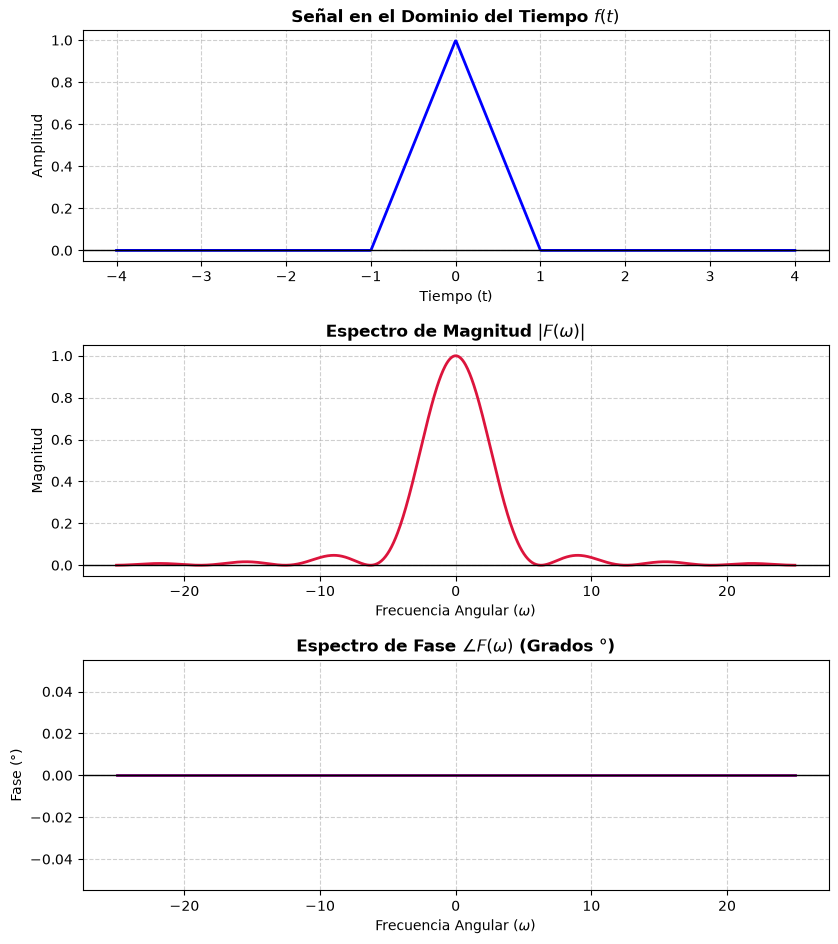

In [10]:
t = sp.Symbol('t', real=True)
w0 = sp.Symbol('w0', real=True)

w0 = 10.0

# Pulso rectangular de ancho 2
f_pulso = sp.Piecewise(
    ((t+1), (t > -1) & (t < 0)), #   <-- se agrega eso para ver el intervalo de t
    ((1-t), (t >= 0) & (t <= 1)),
    (0, True)
)

# Ejecutar análisis y gráficas
res_pulso = analizar_transformada_fourier(
    f_t=f_pulso,
    variable_t=t,
    lim_inf=-1,
    lim_sup=1,
    t_rango=(-4, 4),
    w_rango=(-25, 25)
)

 RESULTADOS SIMBÓLICOS DE LA TRANSFORMADA


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

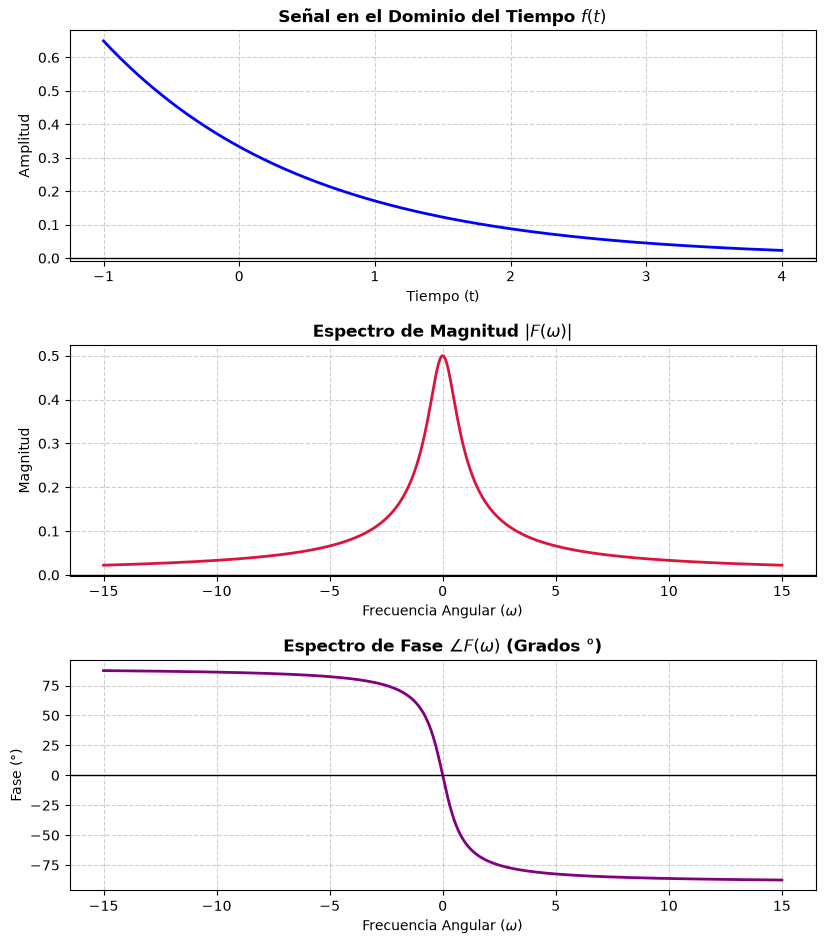

In [3]:
t = sp.Symbol('t', real=True)
a = sp.Symbol('a', real=True, positive=True) # Definir 'a' como real positiva

# Para a = 2 (evaluando numéricamente):
f_exp = (1/3) * sp.exp(-(2/3) * t)

# Como es causal u(t), integramos desde 0 hasta infinito
res_exp = analizar_transformada_fourier(
    f_t=f_exp,
    variable_t=t,
    lim_inf=0,        # u(t) activa el límite en 0
    lim_sup=sp.oo,    # Hasta infinito
    t_rango=(-1, 4),
    w_rango=(-15, 15)
)

 1. RESULTADOS SIMBÓLICOS DE LA TRANSFORMADA


<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

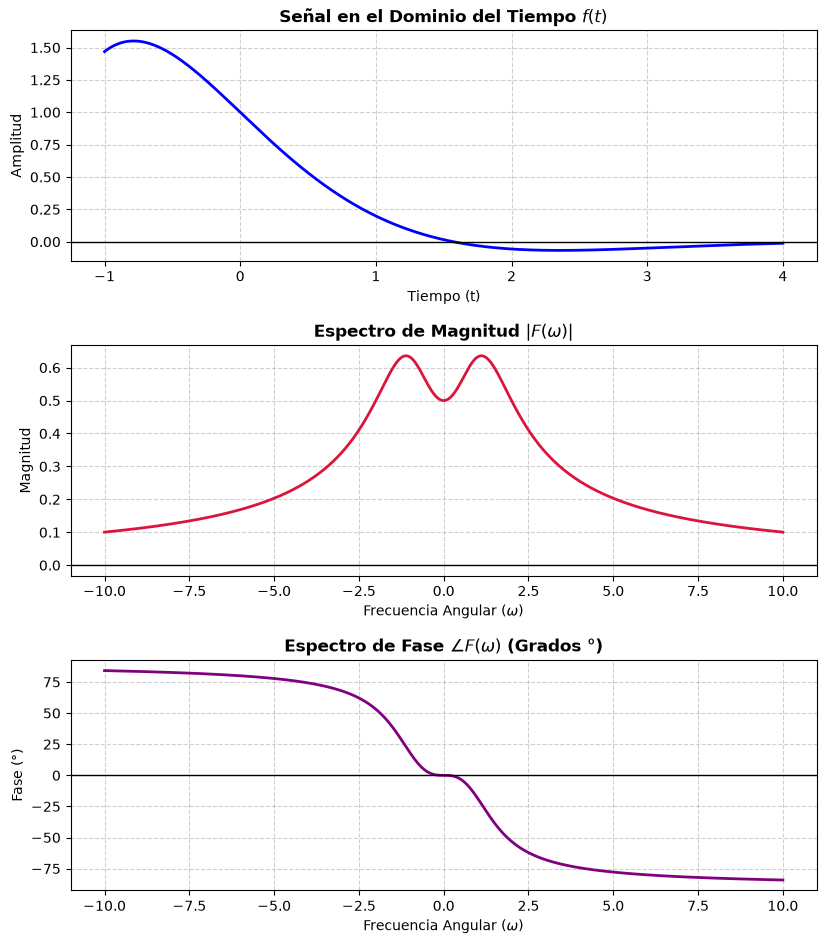

In [19]:
import sympy as sp

t = sp.Symbol('t', real=True)
a = sp.Symbol('a', real=True, positive=True) # 'positive=True' es vital para que SymPy sepa que a > 0

f_t = (sp.exp(-t)*(sp.cos(t)))

# Integración desde 0 hasta infinito
resultado = analizar_transformada_fourier(
    f_t=f_t,
    variable_t=t,
    lim_inf=0,
    lim_sup=sp.oo,
    t_rango=(-1, 4),
    w_rango=(-10, 10)
)